# Phase 1: Enhancement (kritikaa, TUMOUR, patient 22)

| Step | This member's algorithms |
|---|---|
| Windowing | **liver window**, level 80 / width 200 (narrower than the abdomen window, so the tumour stands out more) |
| Spatial filter | **bilateral** (edge-preserving) vs **Gaussian** blur |
| Contrast | **CLAHE** vs **histogram equalisation** |
| Frequency | 2D DFT spectrum + **Butterworth lowpass** (D0 = 50, order 3) |
| Validation | PSNR + CNR (liver vs surroundings, and the main target: **tumour vs liver**) |

In [1]:
import os, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

NAME = "kritikaa"
SLICES = f"../data/slices/{NAME}"
OUT = "outputs_kritikaa"
FIGS = "../report/figures/kritikaa"
os.makedirs(f"{OUT}/enhanced", exist_ok=True)
os.makedirs(FIGS, exist_ok=True)

files = sorted(glob.glob(f"{SLICES}/*_ct.npy"))
print(len(files), "slices found")

def load(ct_path):
    base = ct_path.replace("_ct.npy", "")
    return np.load(ct_path), cv2.imread(base + "_liver.png", 0) > 0, cv2.imread(base + "_tumour.png", 0) > 0

example = max(files, key=lambda f: load(f)[2].sum())     # slice with the biggest tumour
ct, liver, tumour = load(example)
print("example slice:", os.path.basename(example), "| tumour pixels:", tumour.sum())
print("median HU  liver:", np.median(ct[liver & ~tumour]), " tumour:", np.median(ct[tumour]))

12 slices found


example slice: p22_s132_ct.npy | tumour pixels: 1239
median HU  liver: 104.0  tumour: 43.0


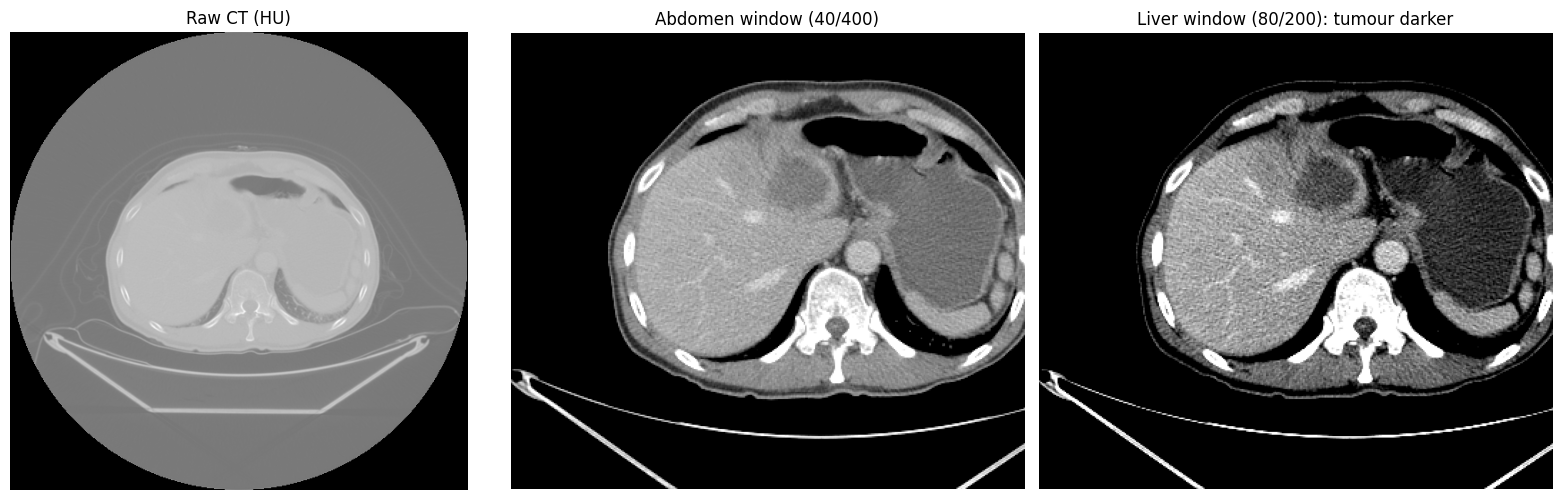

In [2]:
def window(ct, level=80, width=200):
    lo, hi = level - width / 2, level + width / 2          # 80, 200 -> -20 to 180 HU
    return ((np.clip(ct, lo, hi) - lo) / (hi - lo) * 255).astype(np.uint8)

def crop(img):
    return img[100:420, 40:400]

def abdomen(ct):
    return ((np.clip(ct, -160, 240) + 160) / 400 * 255).astype(np.uint8)

win = window(ct)
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].imshow(ct, cmap="gray"); ax[0].set_title("Raw CT (HU)")
ax[1].imshow(crop(abdomen(ct)), cmap="gray"); ax[1].set_title("Abdomen window (40/400)")
ax[2].imshow(crop(win), cmap="gray"); ax[2].set_title("Liver window (80/200): tumour darker")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_windowing.png", dpi=120); plt.show()

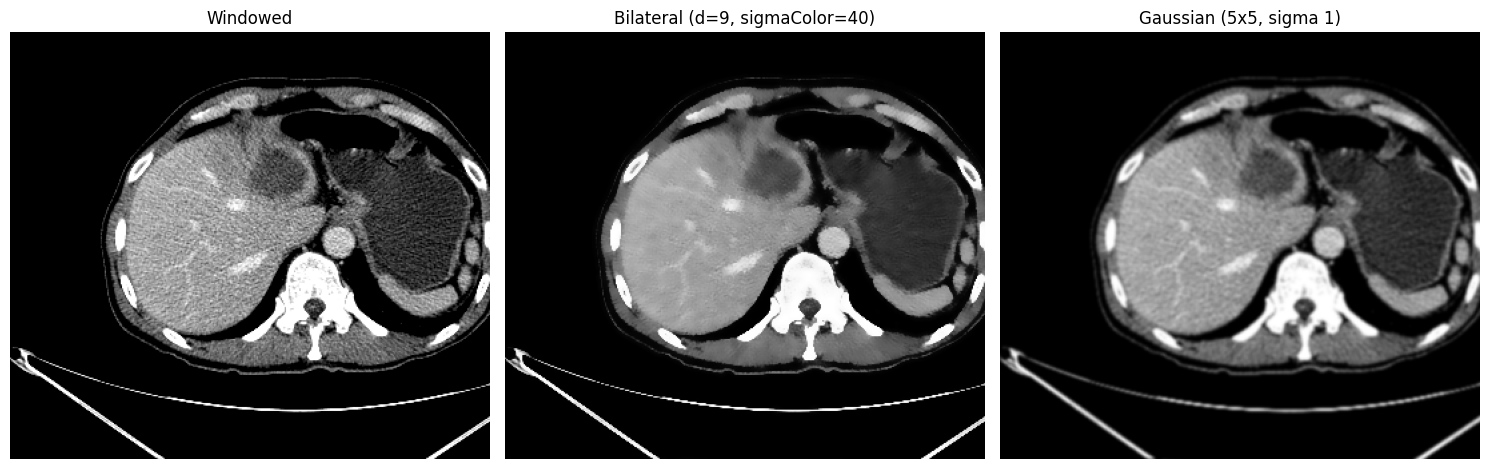

In [3]:
bilateral = cv2.bilateralFilter(win, d=9, sigmaColor=40, sigmaSpace=9)
gauss = cv2.GaussianBlur(win, (5, 5), 1)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, im, t in zip(ax, [win, bilateral, gauss], ["Windowed", "Bilateral (d=9, sigmaColor=40)", "Gaussian (5x5, sigma 1)"]):
    a.imshow(crop(im), cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_spatial_filters.png", dpi=120); plt.show()

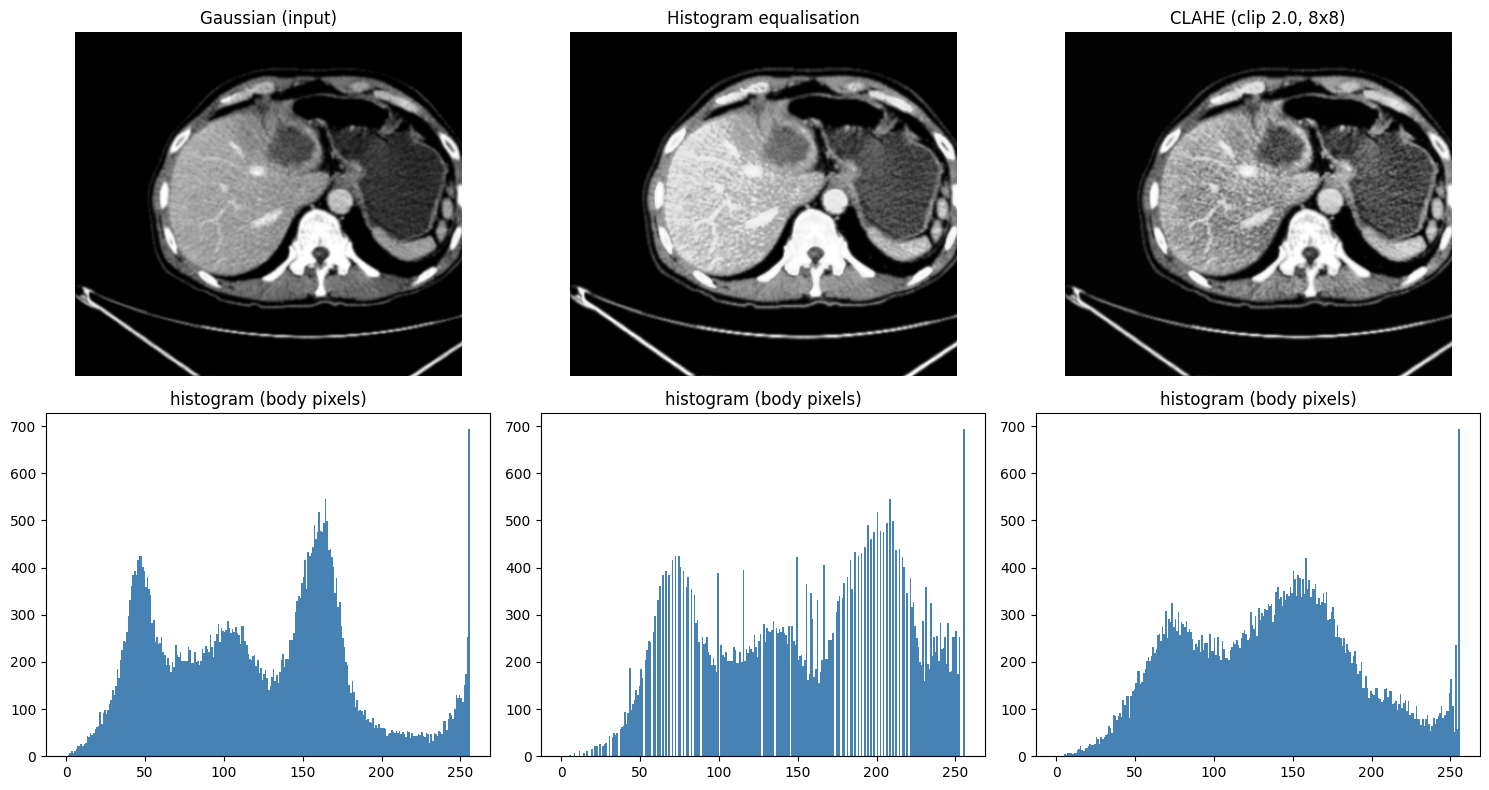

In [4]:
he = cv2.equalizeHist(gauss)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gauss)
body = win > 0
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for j, (im, t) in enumerate([(gauss, "Gaussian (input)"), (he, "Histogram equalisation"), (clahe, "CLAHE (clip 2.0, 8x8)")]):
    ax[0, j].imshow(crop(im), cmap="gray"); ax[0, j].set_title(t); ax[0, j].axis("off")
    ax[1, j].hist(im[body].ravel(), bins=256, range=(0, 256), color="steelblue"); ax[1, j].set_title("histogram (body pixels)")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_contrast.png", dpi=120); plt.show()

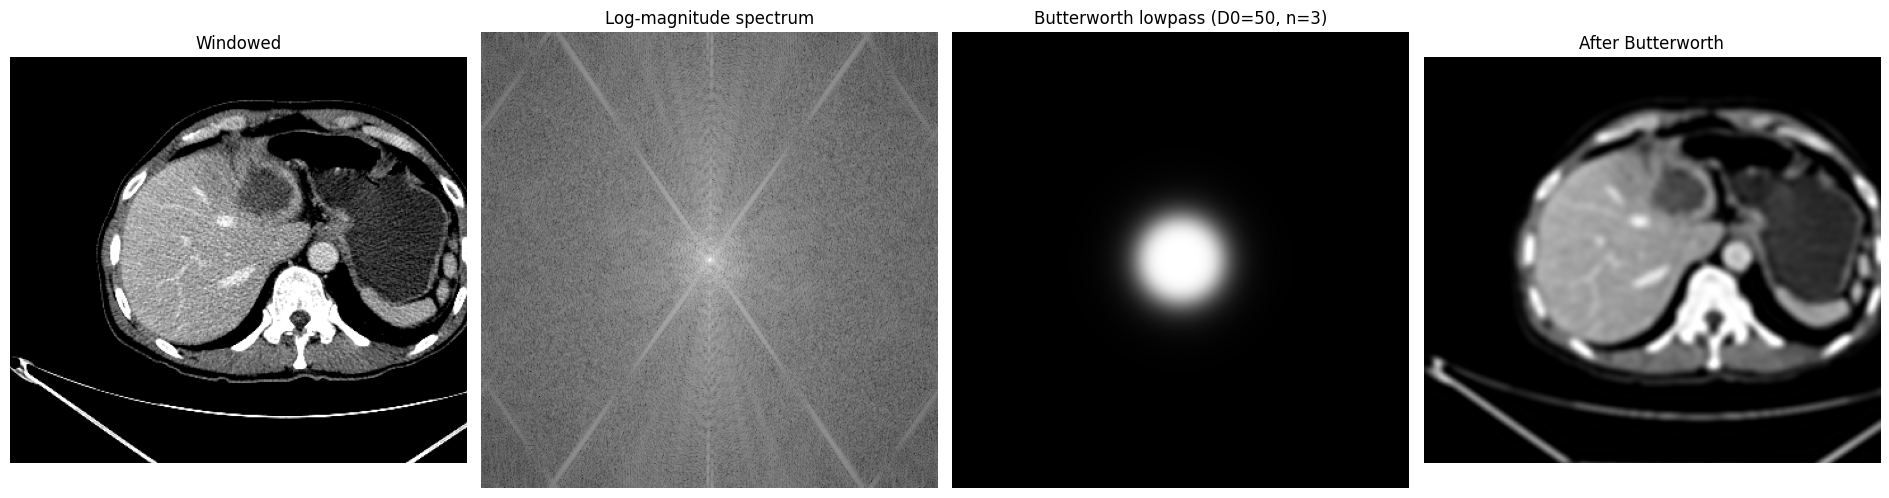

In [5]:
def butterworth_lowpass(img, D0=50, n=3):
    """Keep low frequencies (smooth shapes), cut high ones (noise)."""
    F = np.fft.fftshift(np.fft.fft2(img.astype(np.float64)))
    rows, cols = img.shape
    u, v = np.meshgrid(np.arange(cols) - cols / 2, np.arange(rows) - rows / 2)
    D = np.sqrt(u ** 2 + v ** 2)
    H = 1 / (1 + (D / D0) ** (2 * n))
    out = np.real(np.fft.ifft2(np.fft.ifftshift(F * H)))
    return np.clip(out, 0, 255).astype(np.uint8), F, H

butter, F, H = butterworth_lowpass(win)
fig, ax = plt.subplots(1, 4, figsize=(19, 5))
ax[0].imshow(crop(win), cmap="gray"); ax[0].set_title("Windowed")
ax[1].imshow(np.log(1 + np.abs(F)), cmap="gray"); ax[1].set_title("Log-magnitude spectrum")
ax[2].imshow(H, cmap="gray"); ax[2].set_title("Butterworth lowpass (D0=50, n=3)")
ax[3].imshow(crop(butter), cmap="gray"); ax[3].set_title("After Butterworth")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_frequency.png", dpi=120); plt.show()

In [6]:
def psnr(ref, test):
    """How close the processed image stays to the original (dB). Higher = less changed."""
    mse = np.mean((ref.astype(np.float64) - test.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255 ** 2 / mse)

def cnr(img, region, background):
    """How well a region stands out from its background. Higher = easier to see."""
    a, b = img[region].astype(np.float64), img[background].astype(np.float64)
    if len(a) == 0 or len(b) == 0:
        return np.nan
    return abs(a.mean() - b.mean()) / np.sqrt(a.var() + b.var() + 1e-9)

rows = []
for f in files:
    ct, liver, tumour = load(f)
    win = window(ct)
    ga = cv2.GaussianBlur(win, (5, 5), 1)
    versions = {"windowed": win, "bilateral": cv2.bilateralFilter(win, 9, 40, 9), "gaussian": ga,
                "butterworth": butterworth_lowpass(win)[0], "gauss+HE": cv2.equalizeHist(ga),
                "gauss+CLAHE": cv2.createCLAHE(2.0, (8, 8)).apply(ga)}
    ring = cv2.dilate(liver.astype(np.uint8), np.ones((25, 25), np.uint8)).astype(bool) & ~liver
    for method, im in versions.items():
        rows.append({"slice": os.path.basename(f)[:-7], "method": method,
                     "PSNR": np.nan if method == "windowed" else psnr(win, im),
                     "CNR liver vs surroundings": cnr(im, liver, ring),          # soft tissue vs background
                     "CNR tumour vs liver": cnr(im, tumour, liver & ~tumour)})
results = pd.DataFrame(rows)
results.to_csv(f"{OUT}/phase1_metrics.csv", index=False)
print(results.groupby("method", sort=False)[["PSNR", "CNR liver vs surroundings", "CNR tumour vs liver"]].mean().round(2))

              PSNR  CNR liver vs surroundings  CNR tumour vs liver
method                                                            
windowed       NaN                       0.72                 1.69
bilateral    31.78                       0.75                 2.38
gaussian     26.95                       0.79                 2.32
butterworth  23.46                       0.80                 2.41
gauss+HE     22.97                       0.90                 2.17
gauss+CLAHE  24.56                       0.70                 1.93


**Final enhancement chosen:** liver window -> Gaussian -> CLAHE. The filters alone give the highest tumour CNR, but in Phase 2 the CLAHE version gave the best tumour segmentation, because CLAHE makes the dark tumour region more uniform inside the liver.

In [7]:
for f in files:
    ct, _, _ = load(f)
    enh = cv2.createCLAHE(2.0, (8, 8)).apply(cv2.GaussianBlur(window(ct), (5, 5), 1))
    cv2.imwrite(f"{OUT}/enhanced/{os.path.basename(f).replace('_ct.npy', '_enh.png')}", enh)
print("saved", len(files), "enhanced slices to", f"{OUT}/enhanced")

saved 12 enhanced slices to outputs_kritikaa/enhanced
